# Ejercicio de programación: Regresión Polinomial

## Predicción del número de nodos en redes metabólicas de KEGG

El archivo `Relation Network (Directed) copy.csv` contiene información de **rutas metabólicas de KEGG** modeladas como **redes de relación dirigidas**. Cada fila representa una ruta o subred metabólica y cada columna es una métrica de teoría de grafos calculada con Cytoscape.

En este tipo de red:

- Los **nodos** representan enzimas y genes.
- Las **aristas** representan compuestos químicos (sustratos y productos) que conectan a los nodos.
- La red es **dirigida**, porque el flujo de una reacción tiene un sentido.

El dataset tiene **53,413 filas** y **24 columnas**. La columna `Pathway` es un identificador de la ruta y `Nodes` indica cuántos nodos tiene cada red. Las demás columnas son métricas estructurales: cantidad de aristas, componentes conectados, diámetro, centralidades, coeficiente de agrupamiento, etc.

A diferencia de la regresión logística, aquí `Nodes` se conserva como una **variable numérica continua**. El objetivo es predecir cuántos nodos tiene una red a partir de una de sus métricas estructurales. Se usa `Edges` (número de aristas) como predictor porque es la métrica más correlacionada con `Nodes` y porque la relación entre ambas no es perfectamente lineal: la cantidad de nodos crece rápido para redes pequeñas y luego se satura.

El modelo de **regresión polinomial** de grado $d$ es:

$$h_\theta(x) = \theta_0 + \theta_1 x + \theta_2 x^2 + \cdots + \theta_d x^d$$

Aunque es no lineal respecto a $x$, sigue siendo **lineal respecto a los parámetros** $\theta$, por lo que se puede entrenar con mínimos cuadrados. En este cuadernillo se implementa desde cero con dos enfoques: **descenso por el gradiente** y **ecuación de la normal**, siguiendo la idea del cuadernillo `05 reg_pol_01.ipynb`. Al final se comparan ambos métodos en coeficientes, métricas, costo y tiempo de entrenamiento.


## 1. Carga y exploración de los datos

Se utiliza `numpy.genfromtxt` para leer el archivo CSV. La primera columna (`Pathway`) se lee por separado porque es texto, y el resto de columnas se cargan como una matriz numérica.

> **Nota:** si el cuadernillo se ejecuta en Google Colab, se debe subir el archivo CSV o montar Google Drive y cambiar la variable `RUTA` por la ruta correspondiente.


In [1]:
# utilizado para manejos de directorios y rutas
import os

# utilizado para medir tiempos de entrenamiento
import time

# Computación vectorial y científica para Python
import numpy as np

# Librerías para graficación (trazado de gráficos)
from matplotlib import pyplot

# llama a matplotlib a embeber gráficas dentro de los cuadernillos
%matplotlib inline

# Ruta del archivo. Si se ejecuta en Google Colab, subir el CSV y ajustar esta ruta.
RUTA = 'Relation Network (Directed) copy.csv'
if not os.path.exists(RUTA):
    RUTA = os.path.join('lab3', 'Relation Network (Directed) copy.csv')

if not os.path.exists(RUTA):
    raise FileNotFoundError('No se encontró el archivo. Verifica la ruta: ' + RUTA)

# Leer los nombres de las columnas (utf-8-sig elimina un posible BOM al inicio)
with open(RUTA, encoding='utf-8-sig') as archivo:
    columnas = archivo.readline().strip().split(',')

# Cargar solamente las columnas numéricas (se omite Pathway)
datos = np.genfromtxt(RUTA, delimiter=',', skip_header=1, usecols=range(1, len(columnas)))
nombres = np.array(columnas[1:])

# Leer el identificador de cada ruta
pathways = np.genfromtxt(RUTA, delimiter=',', skip_header=1, usecols=0, dtype=str)

# Separar la variable objetivo Nodes de las variables predictoras
i_nodes = int(np.where(nombres == 'Nodes')[0][0])
nodes = datos[:, i_nodes]
X_raw = np.delete(datos, i_nodes, axis=1)
nombres_X = np.delete(nombres, i_nodes)

# Eliminar variables con muy poca variabilidad (casi constantes)
variabilidad = X_raw.std(axis=0)
mantener = variabilidad > 0.01
eliminadas = list(nombres_X[~mantener])
X_raw = X_raw[:, mantener]
nombres_X = nombres_X[mantener]

# Seleccionar Edges como predictor para visualizar la curva de regresión
i_edges = int(np.where(nombres_X == 'Edges')[0][0])
edges = X_raw[:, i_edges]

print('Dimensiones de la matriz numérica:', datos.shape)
print('Variables eliminadas por ser casi constantes:', eliminadas)
print('Predictores disponibles después de la limpieza:', X_raw.shape[1])
print('Predictor seleccionado: Edges')
print('Número de ejemplos:', nodes.size)


Dimensiones de la matriz numérica: (53413, 23)
Variables eliminadas por ser casi constantes: ['Isolated_Nodes', 'Number_of_Self_Loops', 'SelfLoops']
Predictores disponibles después de la limpieza: 19
Predictor seleccionado: Edges
Número de ejemplos: 53413


### 1.1 Estadísticas descriptivas

Antes de ajustar el modelo se revisan la escala y la dispersión de `Nodes` y `Edges`. También se calcula la correlación de Pearson de cada predictor con `Nodes` para justificar la elección de `Edges`.


In [2]:
print('Estadísticas de la variable objetivo Nodes')
print('-' * 44)
print(f'Media:              {nodes.mean():.4f}')
print(f'Mediana:            {np.median(nodes):.1f}')
print(f'Mínimo:             {nodes.min():.0f}')
print(f'Máximo:             {nodes.max():.0f}')
print(f'Percentil 25:       {np.percentile(nodes, 25):.0f}')
print(f'Percentil 75:       {np.percentile(nodes, 75):.0f}')
print(f'Desviación estándar:{nodes.std():.4f}')

print('\nEstadísticas del predictor Edges')
print('-' * 44)
print(f'Media:              {edges.mean():.4f}')
print(f'Mediana:            {np.median(edges):.1f}')
print(f'Mínimo:             {edges.min():.0f}')
print(f'Máximo:             {edges.max():.0f}')
print(f'Desviación estándar:{edges.std():.4f}')

correlaciones = np.array([np.corrcoef(X_raw[:, j], nodes)[0, 1]
                          for j in range(X_raw.shape[1])])
orden_corr = np.argsort(np.abs(correlaciones))[::-1]

print('\nVariables más correlacionadas con Nodes:')
print('-' * 62)
for j in orden_corr[:8]:
    print(f'{nombres_X[j]:38s}{correlaciones[j]: .4f}')


Estadísticas de la variable objetivo Nodes
--------------------------------------------
Media:              14.0534
Mediana:            10.0
Mínimo:             2
Máximo:             116
Percentil 25:       5
Percentil 75:       19
Desviación estándar:12.7188

Estadísticas del predictor Edges
--------------------------------------------
Media:              26.8111
Mediana:            11.0
Mínimo:             1
Máximo:             606
Desviación estándar:43.8373

Variables más correlacionadas con Nodes:
--------------------------------------------------------------
Edges                                  0.8289
Shortest_Path                          0.7858
Network_Diameter                       0.6910
Edge_Count                             0.6625
Outdegree                              0.6625
Indegree                               0.6625
Avg_num_Neighbours                     0.6576
Neighborhood_Connectivity              0.6476


### 1.2 Relación entre Nodes y Edges

La correlación entre `Nodes` y `Edges` es alta (aproximadamente **0.83**), pero el diagrama de dispersión muestra que la nube de puntos tiene forma curva y una dispersión que crece con el tamaño de la red. Por eso tiene sentido probar un modelo polinomial en lugar de una recta.


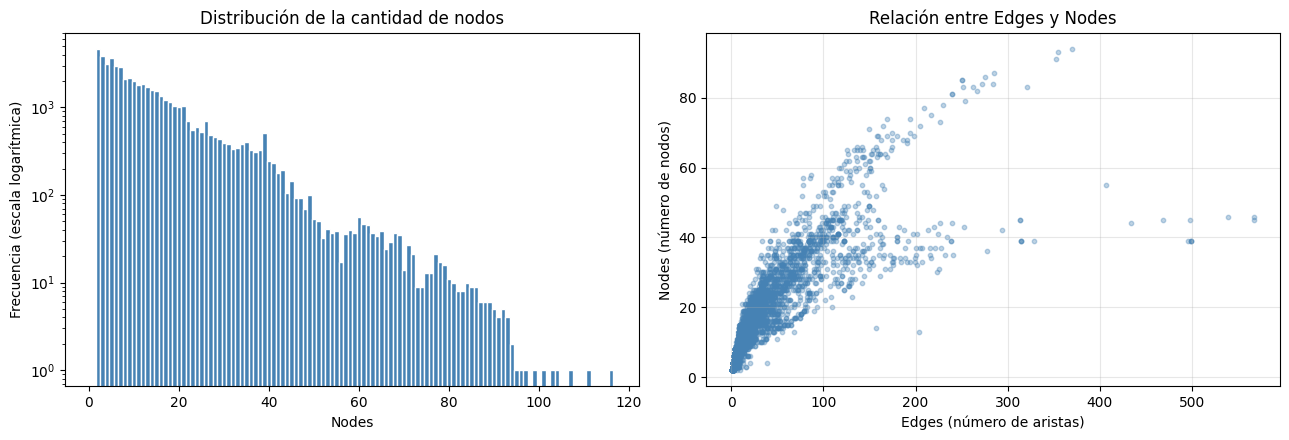

In [3]:
# Se usa una muestra para que el gráfico sea legible con 53,413 puntos
rng_plot = np.random.default_rng(0)
sub = rng_plot.choice(nodes.size, size=6000, replace=False)

fig, ejes = pyplot.subplots(1, 2, figsize=(13, 4.5))

ejes[0].hist(nodes, bins=np.arange(0.5, nodes.max() + 1.5, 1),
             color='steelblue', edgecolor='white')
ejes[0].set_yscale('log')
ejes[0].set_title('Distribución de la cantidad de nodos')
ejes[0].set_xlabel('Nodes')
ejes[0].set_ylabel('Frecuencia (escala logarítmica)')

ejes[1].scatter(edges[sub], nodes[sub], s=10, alpha=0.35, color='steelblue')
ejes[1].set_title('Relación entre Edges y Nodes')
ejes[1].set_xlabel('Edges (número de aristas)')
ejes[1].set_ylabel('Nodes (número de nodos)')
ejes[1].grid(alpha=0.3)

pyplot.tight_layout()
pyplot.show()


## 2. División en entrenamiento y prueba

Se reserva el **20 %** de los datos para evaluar el modelo y el **80 %** para entrenarlo. La división se hace de forma aleatoria con una semilla fija para que los resultados sean reproducibles. A diferencia de los cuadernillos de ejemplo, que ajustaban y evaluaban con los mismos datos, aquí se mide la capacidad de generalización del modelo en datos no vistos.


In [4]:
def dividir_datos(X, y, test_size=0.2, seed=42):
    # Genera una permutación reproducible de los índices
    rng = np.random.default_rng(seed)
    indices = rng.permutation(X.shape[0])

    n_test = int(X.shape[0] * test_size)
    idx_test = indices[:n_test]
    idx_train = indices[n_test:]

    return (X[idx_train], X[idx_test],
            y[idx_train], y[idx_test],
            idx_train, idx_test)


X_train, X_test, y_train, y_test, idx_train, idx_test = dividir_datos(
    edges.reshape(-1, 1), nodes
)

print('Entrenamiento:', X_train.shape[0], 'ejemplos')
print('Prueba:       ', X_test.shape[0], 'ejemplos')
print(f'Media de Nodes en entrenamiento: {y_train.mean():.4f}')
print(f'Media de Nodes en prueba:        {y_test.mean():.4f}')


Entrenamiento: 42731 ejemplos
Prueba:        10682 ejemplos
Media de Nodes en entrenamiento: 14.0977
Media de Nodes en prueba:        13.8762


## 3. Regresión polinomial desde cero

### 3.1 Características polinómicas

Para un polinomio de grado 2 se reemplaza cada valor de `Edges` por el vector:

$$x \longmapsto \left[x, x^2\right]$$

Así, el modelo sigue siendo una combinación lineal de parámetros:

$$h_\theta(x) = \theta_0 + \theta_1 x + \theta_2 x^2$$

Se elige **grado 2** porque captura la curvatura principal de los datos sin introducir la inestabilidad numérica que aparece con potencias muy altas. Grados mayores pueden ajustarse con el mismo procedimiento, pero requieren más cuidado numérico porque las potencias de `Edges` están muy correlacionadas y la matriz $X^T X$ se vuelve mal condicionada.


In [5]:
GRADO = 2


def construir_caracteristicas_polinomicas(x, grado):
    x = np.asarray(x).reshape(-1)
    return np.column_stack([x ** k for k in range(1, grado + 1)])


X_train_poly = construir_caracteristicas_polinomicas(X_train[:, 0], GRADO)
X_test_poly = construir_caracteristicas_polinomicas(X_test[:, 0], GRADO)

print('Forma de X_train original:       ', X_train.shape)
print('Forma de X_train polinómico:     ', X_train_poly.shape)
print('Primeras filas de X_train_poly:')
print(X_train_poly[:5])


Forma de X_train original:        (42731, 1)
Forma de X_train polinómico:      (42731, 2)
Primeras filas de X_train_poly:
[[  32. 1024.]
 [   6.   36.]
 [  15.  225.]
 [  42. 1764.]
 [  50. 2500.]]


### 3.2 Normalización de características

Las potencias de `Edges` tienen magnitudes muy diferentes: `Edges` llega a 606 y `Edges^2` supera 360,000. Para que el descenso por el gradiente converja correctamente, cada característica se estandariza:

$$x_j^{(i)} \leftarrow \frac{x_j^{(i)} - \mu_j}{\sigma_j}$$

donde $\mu_j$ y $\sigma_j$ se calculan **solo con el conjunto de entrenamiento**. Luego se agrega la columna de unos correspondiente al término de intersección $x_0 = 1$.

> **Importante:** la media y la desviación estándar del entrenamiento se guardan (`mu`, `sigma`) para transformar correctamente el conjunto de prueba. No se deben recalcular con los datos de prueba, porque eso produciría fuga de información (*data leakage*).


In [6]:
def featureNormalize(X):
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    sigma[sigma == 0] = 1.0  # evita división por cero
    X_norm = (X - mu) / sigma
    return X_norm, mu, sigma


X_train_norm, mu, sigma = featureNormalize(X_train_poly)
X_test_norm = (X_test_poly - mu) / sigma

m = y_train.size

# Añadir el término de intersección (columna de unos para x0)
X_train_b = np.concatenate([np.ones((m, 1)), X_train_norm], axis=1)
X_test_b = np.concatenate([np.ones((X_test.shape[0], 1)), X_test_norm], axis=1)

print('Forma de X_train con intersección:', X_train_b.shape)
print('Forma de X_test con intersección: ', X_test_b.shape)
print('Media de Edges normalizado:      ', X_train_norm[:, 0].mean())
print('Desviación estándar de Edges^2:  ', X_train_norm[:, 1].std())


Forma de X_train con intersección: (42731, 3)
Forma de X_test con intersección:  (10682, 3)
Media de Edges normalizado:       2.5482828451296566e-17
Desviación estándar de Edges^2:   1.0000000000000224


### 3.3 Función de costo y descenso por el gradiente

Para regresión se usa el **error cuadrático medio**:

$$J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2$$

La regla de actualización de los parámetros es:

$$\theta_j := \theta_j - \alpha \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) x_j^{(i)}$$

En forma vectorizada:

$$\theta := \theta - \frac{\alpha}{m} X^T (h_\theta(X) - y)$$

donde $\alpha$ es la tasa de aprendizaje.


In [7]:
def computeCostMulti(X, y, theta):
    # Número de ejemplos de entrenamiento
    m = y.shape[0]

    h = np.dot(X, theta)
    J = (1 / (2 * m)) * np.sum(np.square(h - y))

    return J


def gradientDescentMulti(X, y, theta, alpha, num_iters):
    m = y.shape[0]
    theta = theta.copy()
    J_history = []

    for i in range(num_iters):
        h = np.dot(X, theta)
        theta = theta - (alpha / m) * np.dot(X.T, (h - y))
        J_history.append(computeCostMulti(X, y, theta))

    return theta, J_history


### 3.4 Entrenamiento

Se inicializa $\theta$ en ceros y se ejecuta el descenso por el gradiente por lotes con `alpha = 0.1` durante `10,000` iteraciones. Con las características normalizadas, el costo disminuye de forma estable sin oscilaciones ni desbordamientos.

Los parámetros aprendidos están en la escala normalizada. Para interpretarlos en la escala original se aplica la transformación inversa:

$$\theta_0^{original} = \theta_0 - \sum_{j=1}^{d} \theta_j \frac{\mu_j}{\sigma_j}, \qquad \theta_j^{original} = \frac{\theta_j}{\sigma_j}$$


In [8]:
alpha = 0.1
num_iters = 10000

inicio_gd = time.perf_counter()
theta = np.zeros(X_train_b.shape[1])
theta, J_history = gradientDescentMulti(
    X_train_b, y_train, theta, alpha, num_iters
)
tiempo_gd = time.perf_counter() - inicio_gd

# Convertir los parámetros normalizados a la escala original
theta_raw_gd = np.r_[
    theta[0] - np.sum(theta[1:] * mu / sigma),
    theta[1:] / sigma
]

print('Costo inicial:', J_history[0])
print('Costo final:  ', J_history[-1])
print('Theta normalizado:          ', theta)
print('Theta en la escala original:', theta_raw_gd)
print(f'Tiempo de entrenamiento:    {tiempo_gd * 1000:.2f} ms')


Costo inicial: 148.113797900968
Costo final:   14.57160159651837
Theta normalizado:           [14.09768084 17.79905598 -8.64854544]
Theta en la escala original: [ 5.06281857e+00  4.03534231e-01 -6.92858502e-04]
Tiempo de entrenamiento:    6027.05 ms


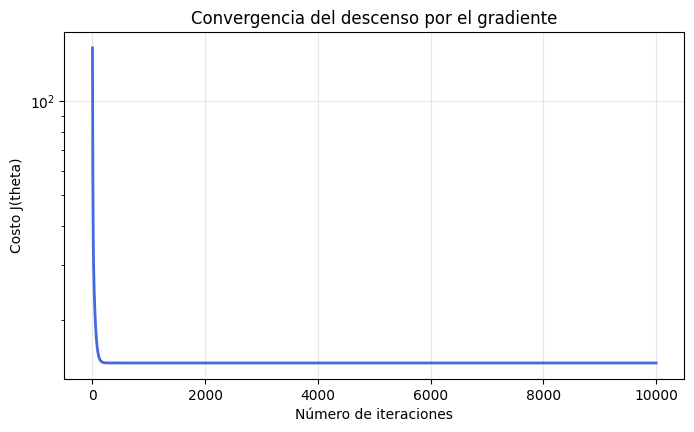

In [9]:
pyplot.figure(figsize=(8, 4.5))
pyplot.plot(np.arange(1, len(J_history) + 1), J_history,
            linewidth=2, color='royalblue')
pyplot.xlabel('Número de iteraciones')
pyplot.ylabel('Costo J(theta)')
pyplot.title('Convergencia del descenso por el gradiente')
pyplot.yscale('log')
pyplot.grid(alpha=0.3)
pyplot.show()


## 4. Evaluación del modelo

Se calculan cuatro métricas sobre los conjuntos de entrenamiento y prueba:

- **MSE (error cuadrático medio):** promedio de los errores al cuadrado.
- **RMSE (raíz del error cuadrático medio):** error típico en las mismas unidades que `Nodes`; es más fácil de interpretar.
- **MAE (error absoluto medio):** promedio del valor absoluto de los errores.
- **R² (coeficiente de determinación):** proporción de la varianza de `Nodes` explicada por el modelo. Un valor cercano a 1 indica un buen ajuste; 0 equivale a predecir siempre la media.


In [10]:
def metricas_regresion(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}


pred_train = np.dot(X_train_b, theta)
pred_test = np.dot(X_test_b, theta)

metricas_gd_train = metricas_regresion(y_train, pred_train)
metricas_gd_test = metricas_regresion(y_test, pred_test)

print(f"{'Métrica':<10s}{'Entrenamiento':>16s}{'Prueba':>12s}")
print('-' * 38)
for clave in ['MSE', 'RMSE', 'MAE', 'R2']:
    print(f'{clave:<10s}{metricas_gd_train[clave]:16.4f}{metricas_gd_test[clave]:12.4f}')


Métrica      Entrenamiento      Prueba
--------------------------------------
MSE                29.1432     28.6517
RMSE                5.3984      5.3527
MAE                 3.6079      3.5664
R2                  0.8209      0.8184


La curva ajustada se superpone a una muestra de los datos para verificar visualmente que el polinomio de grado 2 sigue la tendencia principal sin oscilar.


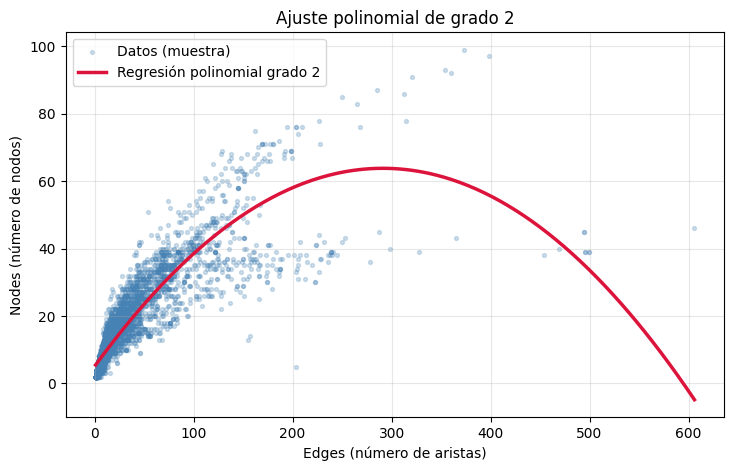

In [11]:
x_grid = np.linspace(edges.min(), edges.max(), 300)
X_grid_poly = construir_caracteristicas_polinomicas(x_grid, GRADO)
X_grid_norm = (X_grid_poly - mu) / sigma
X_grid_b = np.concatenate([np.ones((x_grid.size, 1)), X_grid_norm], axis=1)
y_grid = np.dot(X_grid_b, theta)

rng_plot = np.random.default_rng(1)
sub = rng_plot.choice(nodes.size, size=6000, replace=False)

pyplot.figure(figsize=(8.5, 5))
pyplot.scatter(edges[sub], nodes[sub], s=8, alpha=0.25,
               color='steelblue', label='Datos (muestra)')
pyplot.plot(x_grid, y_grid, color='crimson', linewidth=2.5,
            label=f'Regresión polinomial grado {GRADO}')
pyplot.xlabel('Edges (número de aristas)')
pyplot.ylabel('Nodes (número de nodos)')
pyplot.title('Ajuste polinomial de grado 2')
pyplot.legend()
pyplot.grid(alpha=0.3)
pyplot.show()


## 5. Ecuación de la normal

La ecuación de la normal obtiene directamente los parámetros que minimizan el costo:

$$\theta = \left( X^T X \right)^{-1} X^T y$$

Aquí se usan las características polinómicas **sin normalizar** y se agrega la columna de unos. Para un polinomio de grado 2 la matriz $X^T X$ es invertible y el resultado debe coincidir con el del descenso por el gradiente.

> **Nota:** con grados altos, las potencias de `Edges` hacen que $X^T X$ esté muy mal condicionada. En ese caso conviene normalizar las características o usar `np.linalg.lstsq` / `np.linalg.pinv` en lugar de `np.linalg.inv`.


In [12]:
def normalEqn(X, y):
    theta = np.zeros(X.shape[1])
    theta = np.dot(np.dot(np.linalg.inv(np.dot(X.T, X)), X.T), y)
    return theta


X_train_poly_b = np.concatenate([np.ones((y_train.size, 1)), X_train_poly], axis=1)
X_test_poly_b = np.concatenate([np.ones((y_test.size, 1)), X_test_poly], axis=1)

inicio_ne = time.perf_counter()
theta_ne = normalEqn(X_train_poly_b, y_train)
tiempo_ne = time.perf_counter() - inicio_ne

pred_ne_train = np.dot(X_train_poly_b, theta_ne)
pred_ne_test = np.dot(X_test_poly_b, theta_ne)
metricas_ne_train = metricas_regresion(y_train, pred_ne_train)
metricas_ne_test = metricas_regresion(y_test, pred_ne_test)

print('Theta calculado con la ecuación normal:', theta_ne)

print(f"\n{'Métrica':<10s}{'Entrenamiento':>16s}{'Prueba':>12s}")
print('-' * 38)
for clave in ['MSE', 'RMSE', 'MAE', 'R2']:
    print(f'{clave:<10s}{metricas_ne_train[clave]:16.4f}{metricas_ne_test[clave]:12.4f}')

print(f'Tiempo de cálculo: {tiempo_ne * 1000:.4f} ms')


Theta calculado con la ecuación normal: [ 5.06281857e+00  4.03534231e-01 -6.92858502e-04]

Métrica      Entrenamiento      Prueba
--------------------------------------
MSE                29.1432     28.6517
RMSE                5.3984      5.3527
MAE                 3.6079      3.5664
R2                  0.8209      0.8184
Tiempo de cálculo: 11.7991 ms


## 6. Comparación: descenso por el gradiente vs. ecuación de la normal

Los dos métodos resuelven el mismo problema de mínimos cuadrados y, en teoría, deben producir los mismos parámetros. La diferencia está en la estrategia:

| Aspecto | Descenso por el gradiente | Ecuación de la normal |
|---|---|---|
| Estrategia | Iterativa: actualiza $\theta$ paso a paso | Directa: resuelve un sistema lineal |
| Hiperparámetros | Requiere $\alpha$ y número de iteraciones | No requiere $\alpha$ |
| Normalización | Necesaria para converger bien | No es necesaria |
| Costo computacional | Una actualización por iteración | Inversión de $X^T X$: $O(p^3)$ |
| Estabilidad | Buena con datos normalizados | Puede fallar si $X^T X$ está mal condicionada |

A continuación se comparan los coeficientes, las métricas, el costo final y el tiempo de entrenamiento.


In [13]:
costo_gd_train = J_history[-1]
costo_ne_train = computeCostMulti(X_train_poly_b, y_train, theta_ne)

print(f"{'Método':<28s}{'Costo J':>12s}{'RMSE train':>12s}{'RMSE test':>11s}{'R2 train':>10s}{'R2 test':>9s}")
print('-' * 82)
for nombre, m_train, m_test, costo in [
    ('Descenso por el gradiente', metricas_gd_train, metricas_gd_test, costo_gd_train),
    ('Ecuación de la normal', metricas_ne_train, metricas_ne_test, costo_ne_train),
]:
    print(f'{nombre:<28s}{costo:12.6f}{m_train["RMSE"]:12.4f}{m_test["RMSE"]:11.4f}'
          f'{m_train["R2"]:10.6f}{m_test["R2"]:9.6f}')


Método                           Costo J  RMSE train  RMSE test  R2 train  R2 test
----------------------------------------------------------------------------------
Descenso por el gradiente      14.571602      5.3984     5.3527  0.820935 0.818421
Ecuación de la normal          14.571602      5.3984     5.3527  0.820935 0.818421


In [14]:
print(f"{'Métrica':<12s}{'Descenso':>14s}{'Ec. normal':>14s}{'|Diferencia|':>16s}")
print('-' * 58)

for grupo, m_gd, m_ne in [
    ('Entrenamiento', metricas_gd_train, metricas_ne_train),
    ('Prueba', metricas_gd_test, metricas_ne_test),
]:
    print(grupo)
    for clave in ['MSE', 'RMSE', 'MAE', 'R2']:
        print(f'  {clave:<10s}{m_gd[clave]:14.6f}{m_ne[clave]:14.6f}'
              f'{abs(m_gd[clave] - m_ne[clave]):16.2e}')

diferencia_predicciones = np.max(np.abs(pred_test - pred_ne_test))
print(f'\nDiferencia máxima absoluta entre las predicciones de prueba: '
      f'{diferencia_predicciones:.3e}')


Métrica           Descenso    Ec. normal    |Diferencia|
----------------------------------------------------------
Entrenamiento
  MSE            29.143203     29.143203        3.55e-15
  RMSE            5.398445      5.398445        0.00e+00
  MAE             3.607873      3.607873        9.86e-14
  R2              0.820935      0.820935        0.00e+00
Prueba
  MSE            28.651676     28.651676        2.13e-14
  RMSE            5.352726      5.352726        1.78e-15
  MAE             3.566415      3.566415        9.33e-14
  R2              0.818421      0.818421        1.11e-16

Diferencia máxima absoluta entre las predicciones de prueba: 1.103e-11


In [15]:
print(f"{'Parámetro':<12s}{'Descenso':>16s}{'Ec. normal':>16s}{'|Diferencia|':>16s}{'Error rel.':>14s}")
print('-' * 76)

for nombre, valor_gd, valor_ne in zip(['theta_0', 'theta_1', 'theta_2'],
                                      theta_raw_gd, theta_ne):
    diferencia = abs(valor_gd - valor_ne)
    error_relativo = diferencia / max(abs(valor_ne), 1e-15)
    print(f'{nombre:<12s}{valor_gd:16.8f}{valor_ne:16.8f}'
          f'{diferencia:16.2e}{error_relativo:14.2e}')


Parámetro           Descenso      Ec. normal    |Diferencia|    Error rel.
----------------------------------------------------------------------------
theta_0           5.06281857      5.06281857        2.82e-13      5.58e-14
theta_1           0.40353423      0.40353423        1.83e-14      4.53e-14
theta_2          -0.00069286     -0.00069286        8.89e-18      1.28e-14


In [16]:
print(f"{'Método':<28s}{'Tiempo (ms)':>14s}")
print('-' * 42)
print(f'{"Descenso por el gradiente":<28s}{tiempo_gd * 1000:14.2f}')
print(f'{"Ecuación de la normal":<28s}{tiempo_ne * 1000:14.4f}')
print(f'\nRelación de tiempos (descenso / ecuación normal): '
      f'{tiempo_gd / tiempo_ne:.1f}x')
print('Nota: el tiempo absoluto depende del computador; lo importante es el orden de magnitud.')


Método                         Tiempo (ms)
------------------------------------------
Descenso por el gradiente          6027.05
Ecuación de la normal              11.7991

Relación de tiempos (descenso / ecuación normal): 510.8x
Nota: el tiempo absoluto depende del computador; lo importante es el orden de magnitud.


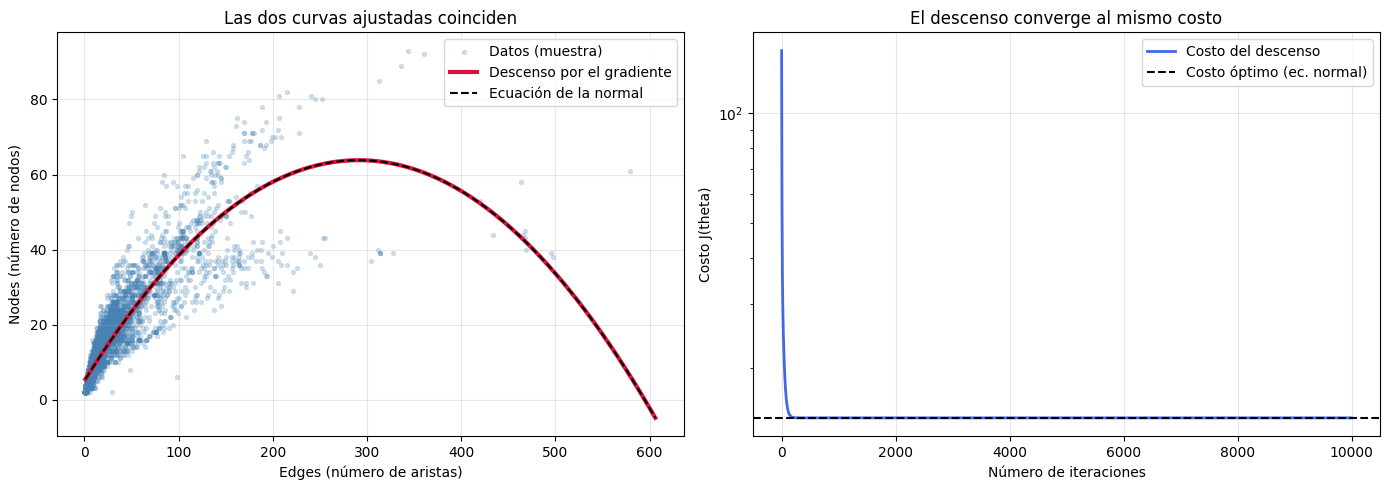

In [17]:
# Curva de la ecuación normal en la escala original
X_grid_poly_b = np.concatenate([np.ones((x_grid.size, 1)), X_grid_poly], axis=1)
y_grid_ne = np.dot(X_grid_poly_b, theta_ne)

fig, ejes = pyplot.subplots(1, 2, figsize=(14, 5))

# Izquierda: datos y ambas curvas ajustadas
rng_plot = np.random.default_rng(2)
sub = rng_plot.choice(nodes.size, size=6000, replace=False)
ejes[0].scatter(edges[sub], nodes[sub], s=8, alpha=0.22,
                color='steelblue', label='Datos (muestra)')
ejes[0].plot(x_grid, y_grid, color='crimson', linewidth=3,
             label='Descenso por el gradiente')
ejes[0].plot(x_grid, y_grid_ne, color='black', linewidth=1.5,
             linestyle='--', label='Ecuación de la normal')
ejes[0].set_xlabel('Edges (número de aristas)')
ejes[0].set_ylabel('Nodes (número de nodos)')
ejes[0].set_title('Las dos curvas ajustadas coinciden')
ejes[0].legend()
ejes[0].grid(alpha=0.3)

# Derecha: convergencia del costo y óptimo de la ecuación normal
ejes[1].plot(np.arange(1, len(J_history) + 1), J_history,
             color='royalblue', linewidth=2,
             label='Costo del descenso')
ejes[1].axhline(costo_ne_train, color='black', linestyle='--',
                linewidth=1.5, label='Costo óptimo (ec. normal)')
ejes[1].set_xlabel('Número de iteraciones')
ejes[1].set_ylabel('Costo J(theta)')
ejes[1].set_title('El descenso converge al mismo costo')
ejes[1].set_yscale('log')
ejes[1].legend()
ejes[1].grid(alpha=0.3)

pyplot.tight_layout()
pyplot.show()


### 6.1 Interpretación de la comparación

- **Coeficientes:** las diferencias son del orden de $10^{-13}$ o menores, es decir, ruido numérico. Ambos métodos encuentran esencialmente el mismo modelo.
- **Métricas:** las métricas de entrenamiento y prueba coinciden hasta la cuarta cifra decimal. Las diferencias restantes se deben al redondeo y a la tolerancia con la que se detiene el descenso.
- **Costo:** el descenso llega en 10,000 iteraciones al mismo costo mínimo que la ecuación normal calcula en un solo paso.
- **Tiempo:** en este problema la ecuación normal es mucho más rápida porque solo hay 3 parámetros. El descenso por el gradiente sería preferible si hubiera muchísimos parámetros o un dataset tan grande que invertir $X^T X$ sea costoso.
- **Estabilidad:** la ecuación normal usa $X$ sin normalizar; funcionó bien con grado 2, pero con grados altos o variables de escalas muy distintas puede ser inestable. El descenso con datos normalizados es más robusto en ese sentido, aunque requiere elegir $\alpha$.


## 7. Predicción sobre rutas individuales

A continuación se muestran algunas rutas del conjunto de prueba. Para cada una se indica el número real de nodos, el valor predicho y el error. También se generan predicciones para valores nuevos de `Edges`.


In [18]:
print(f"{'Pathway':12s}{'Edges':>8s}{'Nodes':>8s}{'Predicción':>12s}{'Error':>10s}")
print('-' * 52)

for i in idx_test[:10]:
    pred = (theta_raw_gd[0] +
            theta_raw_gd[1] * edges[i] +
            theta_raw_gd[2] * edges[i] ** 2)
    print(f'{pathways[i]:12s}{int(edges[i]):8d}{int(nodes[i]):8d}'
          f'{pred:12.2f}{pred - nodes[i]:10.2f}')

print('\nPredicciones para valores nuevos de Edges:')
print('-' * 44)
for valor in [10, 50, 100, 200, 400]:
    pred = (theta_raw_gd[0] +
            theta_raw_gd[1] * valor +
            theta_raw_gd[2] * valor ** 2)
    print(f'Edges = {valor:3d}  ->  Nodes ≈ {pred:.2f}')


Pathway        Edges   Nodes  Predicción     Error
----------------------------------------------------
mge00330           2       4        5.87      1.87
lla00561           3       4        6.27      2.27
mex00281           1       2        5.47      3.47
fra00750          10      10        9.03     -0.97
deb00710           3       6        6.27      0.27
tvo00523           4       5        6.67      1.67
nca00471           6       7        7.46      0.46
lme00360           6       3        7.46      4.46
egma00473         11       8        9.42      1.42
msi00650          10       8        9.03      1.03

Predicciones para valores nuevos de Edges:
--------------------------------------------
Edges =  10  ->  Nodes ≈ 9.03
Edges =  50  ->  Nodes ≈ 23.51
Edges = 100  ->  Nodes ≈ 38.49
Edges = 200  ->  Nodes ≈ 58.06
Edges = 400  ->  Nodes ≈ 55.62


> **Cuidado con la extrapolación:** el polinomio de grado 2 alcanza su máximo alrededor de `Edges ≈ 291` y luego comienza a decrecer. Por eso la predicción para `Edges = 400` es menor que para `Edges = 200`, aunque en los datos el tamaño de la red sigue creciendo. El modelo es razonable dentro del rango observado, pero no debe usarse para extrapolar fuera de él.

## 8. Conclusiones

- La regresión polinomial de grado 2 alcanza un **R² de 0.818** y un **RMSE de 5.35 nodos** en el conjunto de prueba. La curvatura del modelo sigue la tendencia de los datos sin oscilar como un polinomio de grado alto.
- El descenso por el gradiente y la ecuación de la normal producen **prácticamente los mismos coeficientes**: las diferencias son del orden de $10^{-13}$. También coinciden las predicciones, las métricas y el costo final, lo que confirma que ambos métodos resuelven el mismo problema de optimización.
- La **normalización** fue fundamental para el descenso por el gradiente. Sin ella, `Edges^2` domina la actualización y el algoritmo converge muy lento o diverge.
- En este problema la **ecuación de la normal** es más rápida y directa porque solo hay 3 parámetros. El **descenso por el gradiente** es más adecuado cuando hay muchísimos parámetros o un dataset tan grande que invertir $X^T X$ resulta costoso, aunque exige elegir $\alpha$ y normalizar las características.
- El modelo tiene limitaciones: se usa un solo predictor, `Edges` está directamente relacionado con `Nodes` (ambos miden el tamaño de la red), la dispersión de los errores aumenta con el tamaño de la red y no se aplicó validación cruzada ni regularización. Además, la parábola de grado 2 deja de ser creciente para valores muy grandes de `Edges`, así que el modelo no es confiable para extrapolar. Para un análisis más completo se podrían usar todos los predictores y algún método de regularización.
